In [1]:
!pip install pandas numpy matplotlib scikit-learn torch torchvision

  Using cached https://files.pythonhosted.org/packages/ec/6b/63cc3df74987c36fe26157ee12e09e8f9db4de771e0f3404263117e75b95/typing_extensions-4.7.1-py3-none-any.whl


In [3]:
!pip install --upgrade scikit-learn -i https://pypi.tuna.tsinghua.edu.cn/simple --user

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
  Using cached https://pypi.tuna.tsinghua.edu.cn/packages/9d/20/0ffe8665a44bce7616bd33d4368a198fecad3b226bcafa38c63ef0f6286f/scikit_learn-1.0.2-cp37-cp37m-win_amd64.whl


In [17]:
import numpy as np

# 方法一：使用原始字符串（推荐）
file_path = r"C:\Users\Lenovo\.jupyter\pems04.npz"

# 读取 npz 文件
data = np.load(file_path)

# 查看文件里包含哪些数组（打印数组名称）
print("数据里的数组名称：", data.files)

# 现在数组名称是 'data'，所以判断和获取都用 'data'
if "data" in data.files:
    flow_data = data["data"]
    print("流量数据的形状：", flow_data.shape)  # 看数据是几行几列
    print("部分流量样本：\n", flow_data[:5, :5])  # 打印前5行、前5列的样本
else:
    print("请检查 npz 文件中流量数组的实际名称～")

数据里的数组名称： ['data']
流量数据的形状： (16992, 307, 3)
部分流量样本：
 [[[6.20e+01 7.70e-03 6.79e+01]
  [5.60e+01 1.12e-02 6.84e+01]
  [9.00e+01 1.43e-02 6.82e+01]
  [3.20e+01 7.40e-03 6.63e+01]
  [1.90e+01 7.30e-03 6.54e+01]]

 [[6.10e+01 7.40e-03 6.73e+01]
  [4.00e+01 8.00e-03 6.86e+01]
  [9.40e+01 1.56e-02 6.78e+01]
  [2.50e+01 5.70e-03 6.57e+01]
  [1.60e+01 6.00e-03 6.68e+01]]

 [[7.10e+01 9.30e-03 6.84e+01]
  [2.80e+01 6.80e-03 6.74e+01]
  [7.90e+01 1.22e-02 6.87e+01]
  [3.60e+01 8.20e-03 6.66e+01]
  [9.00e+00 3.60e-03 6.72e+01]]

 [[8.60e+01 1.12e-02 6.78e+01]
  [4.70e+01 8.90e-03 6.95e+01]
  [9.40e+01 1.48e-02 6.89e+01]
  [4.60e+01 1.04e-02 6.68e+01]
  [1.10e+01 4.40e-03 6.63e+01]]

 [[1.03e+02 1.44e-02 6.74e+01]
  [3.60e+01 8.10e-03 6.81e+01]
  [1.54e+02 2.58e-02 6.73e+01]
  [6.80e+01 1.47e-02 6.70e+01]
  [9.00e+00 3.60e-03 6.84e+01]]]


In [13]:
import os

# 打印 Jupyter 当前的工作目录
print("当前工作目录：", os.getcwd())

当前工作目录： C:\Users\Lenovo


In [18]:
# 1. 重新加载数据（只加载测试集和scaler，跳过训练集）
data_path = ".jupyter/pems04.npz"  # 你的数据集路径
time_step = 12  # 和训练时一致
_, _, test_dataset, scaler, _ = load_pems_data(data_path, time_step)
input_dim = scaler.n_features_in_  # 路段数

# 2. 加载已保存的模型（如果之前保存过）
device = "cuda" if torch.cuda.is_available() else "cpu"
model = CNN_LSTM(input_dim=input_dim, hidden_dim=128, num_layers=2)  # 参数和训练时一致
model.load_state_dict(torch.load("cnn_lstm_model.pth", map_location=device))  # 加载模型权重
model.to(device).eval()  # 切换到评估模式

# 如果没保存模型，但model变量还在内存中，直接用：
# model.eval()

开始加载数据集：.jupyter/pems04.npz
✅ 数据集加载完成！原始流量数据形状：(16992, 307)（时间步×路段数）

随机抽查3个路段的流量统计（原始数据）：
路段62：最小值=0.0, 最大值=619.0, 平均值=302.1
路段61：最小值=0.0, 最大值=171.0, 平均值=49.7
路段6：最小值=23.0, 最大值=534.0, 平均值=278.5

✅ 数据归一化完成！使用MinMaxScaler，特征数=307

✅ 数据集划分完成：
  训练集样本数：11886 | 验证集样本数：2547 | 测试集样本数：2547


CNN_LSTM(
  (cnn): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(19648, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [34]:
# 加载模型（如果已保存）
model = CNN_LSTM(input_dim=input_dim, hidden_dim=128, num_layers=2)
model.load_state_dict(torch.load("cnn_lstm_model.pth", map_location=device))
model.to(device).eval()

# 只评估前5个路段
all_mae = evaluate_all_segments(model, test_dataset, scaler, time_step, device)


===== 快速评估前 5 个路段 =====
路段1-样本0 | 真实值：0.1022 | 预测值：0.1080
路段2-样本0 | 真实值：0.2164 | 预测值：0.1080
路段3-样本0 | 真实值：0.2061 | 预测值：0.1080
路段4-样本0 | 真实值：0.0473 | 预测值：0.1080
路段5-样本0 | 真实值：0.0484 | 预测值：0.1080

前5个路段的平均MAE: 0.73 辆



===== 全路段时段评估 =====


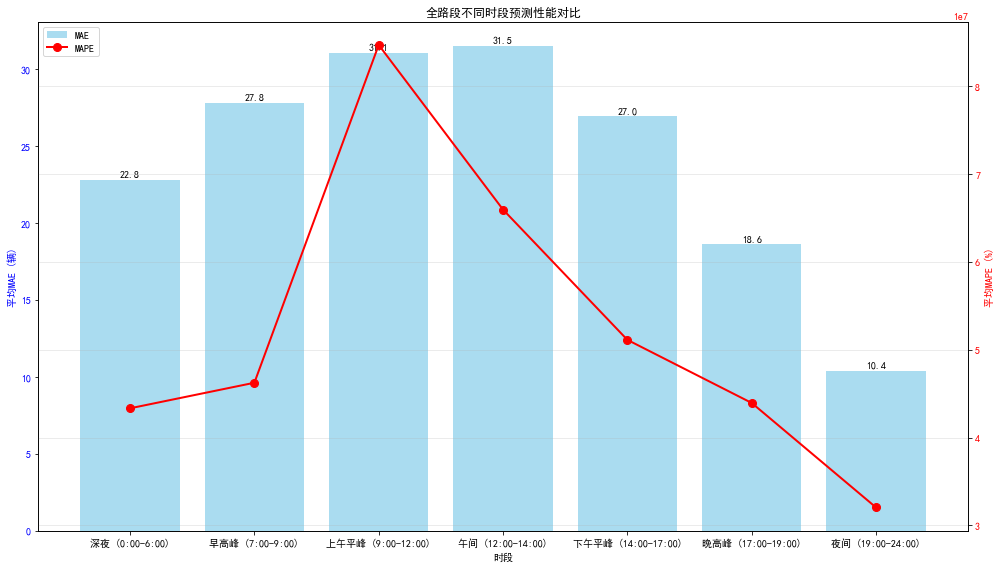


📊 全路段时段性能分析报告

🏆 性能最佳时段 (MAE): 夜间 (19:00-24:00)
   - 平均MAE: 10.41 辆
   - 平均MAPE: 32024885.91%

⚠️  性能最差时段 (MAE): 午间 (12:00-14:00)
   - 平均MAE: 31.52 辆
   - 平均MAPE: 65968473.55%

📈 详细时段分析:
  深夜 (0:00-6:00):
    - MAE: 22.82 ± 16.78 辆
    - MAPE: 43327656.34 ± 293515330.02%
    - 样本数: 648
  早高峰 (7:00-9:00):
    - MAE: 27.83 ± 18.15 辆
    - MAPE: 46240211.90 ± 410646263.67%
    - 样本数: 216
  上午平峰 (9:00-12:00):
    - MAE: 31.06 ± 19.58 辆
    - MAPE: 84735125.36 ± 478779171.12%
    - 样本数: 324
  午间 (12:00-14:00):
    - MAE: 31.52 ± 20.79 辆
    - MAPE: 65968473.55 ± 451354301.23%
    - 样本数: 216
  下午平峰 (14:00-17:00):
    - MAE: 26.96 ± 17.09 辆
    - MAPE: 51126040.12 ± 393524895.31%
    - 样本数: 324
  晚高峰 (17:00-19:00):
    - MAE: 18.62 ± 12.47 辆
    - MAPE: 43935510.64 ± 319205180.21%
    - 样本数: 216
  夜间 (19:00-24:00):
    - MAE: 10.41 ± 8.78 辆
    - MAPE: 32024885.91 ± 121557688.63%
    - 样本数: 495

📋 整体性能总结:
  - 平均MAE: 24.18 辆
  - 平均MAPE: 52479700.55%
  - MAE波动范围: 10.41 - 31.52 辆
  - MAPE波动范围: 

In [9]:
# 原来的调用（注释掉）
# period_metrics = evaluate_time_periods(y_true, y_pred)

# 新的全路段时段评估
print("\n===== 全路段时段评估 =====")
period_results = evaluate_time_periods_all_segments(y_true, y_pred)
visualize_period_performance(period_results)
print_period_analysis(period_results)

🚀 开始CNN-LSTM交通流量预测完整流程
📥 加载数据集：.jupyter/pems04.npz
✅ 原始数据形状：(16992, 307)（时间步×路段数）
📊 原始数据范围：min=0.00, max=919.00

🔍 随机路段流量统计：
  路段108：min=0.0, max=179.0, mean=65.3
  路段200：min=11.0, max=235.0, mean=120.3
  路段75：min=0.0, max=322.0, mean=107.9

✅ 数据归一化完成，路段总数：307

📊 数据集划分：
  训练集：11886样本 | 验证集：2547样本 | 测试集：2547样本

📌 模型参数量: 2,589,907

🚀 开始训练（60轮），设备：cpu
  Epoch 1/60 | 批次 50/372 | 损失: 0.026909
  Epoch 1/60 | 批次 100/372 | 损失: 0.027494
  Epoch 1/60 | 批次 150/372 | 损失: 0.019085
  Epoch 1/60 | 批次 200/372 | 损失: 0.020478
  Epoch 1/60 | 批次 250/372 | 损失: 0.023353
  Epoch 1/60 | 批次 300/372 | 损失: 0.018695
  Epoch 1/60 | 批次 350/372 | 损失: 0.020338
  Epoch 2/60 | 批次 50/372 | 损失: 0.014996
  Epoch 2/60 | 批次 100/372 | 损失: 0.016313
  Epoch 2/60 | 批次 150/372 | 损失: 0.012016
  Epoch 2/60 | 批次 200/372 | 损失: 0.012844
  Epoch 2/60 | 批次 250/372 | 损失: 0.011635
  Epoch 2/60 | 批次 300/372 | 损失: 0.009118
  Epoch 2/60 | 批次 350/372 | 损失: 0.010318
  Epoch 3/60 | 批次 50/372 | 损失: 0.011250
  Epoch 3/60 | 批次 100/372 | 损失: 0.010

  Epoch 27/60 | 批次 150/372 | 损失: 0.002524
  Epoch 27/60 | 批次 200/372 | 损失: 0.002361
  Epoch 27/60 | 批次 250/372 | 损失: 0.002259
  Epoch 27/60 | 批次 300/372 | 损失: 0.002738
  Epoch 27/60 | 批次 350/372 | 损失: 0.002260
  Epoch 28/60 | 批次 50/372 | 损失: 0.002029
  Epoch 28/60 | 批次 100/372 | 损失: 0.002087
  Epoch 28/60 | 批次 150/372 | 损失: 0.002724
  Epoch 28/60 | 批次 200/372 | 损失: 0.002180
  Epoch 28/60 | 批次 250/372 | 损失: 0.002276
  Epoch 28/60 | 批次 300/372 | 损失: 0.002184
  Epoch 28/60 | 批次 350/372 | 损失: 0.002209
  Epoch 29/60 | 批次 50/372 | 损失: 0.001959
  Epoch 29/60 | 批次 100/372 | 损失: 0.001829
  Epoch 29/60 | 批次 150/372 | 损失: 0.002523
  Epoch 29/60 | 批次 200/372 | 损失: 0.001760
  Epoch 29/60 | 批次 250/372 | 损失: 0.002252
  Epoch 29/60 | 批次 300/372 | 损失: 0.002670
  Epoch 29/60 | 批次 350/372 | 损失: 0.002412
Epoch 00029: reducing learning rate of group 0 to 5.0000e-04.
  Epoch 30/60 | 批次 50/372 | 损失: 0.002269
  Epoch 30/60 | 批次 100/372 | 损失: 0.001554
  Epoch 30/60 | 批次 150/372 | 损失: 0.002146
  Epoch 30/60 | 批

  Epoch 54/60 | 批次 50/372 | 损失: 0.002411
  Epoch 54/60 | 批次 100/372 | 损失: 0.001879
  Epoch 54/60 | 批次 150/372 | 损失: 0.002459
  Epoch 54/60 | 批次 200/372 | 损失: 0.001995
  Epoch 54/60 | 批次 250/372 | 损失: 0.002108
  Epoch 54/60 | 批次 300/372 | 损失: 0.001602
  Epoch 54/60 | 批次 350/372 | 损失: 0.002029
  Epoch 55/60 | 批次 50/372 | 损失: 0.001999
  Epoch 55/60 | 批次 100/372 | 损失: 0.002109
  Epoch 55/60 | 批次 150/372 | 损失: 0.002259
  Epoch 55/60 | 批次 200/372 | 损失: 0.002049
  Epoch 55/60 | 批次 250/372 | 损失: 0.002030
  Epoch 55/60 | 批次 300/372 | 损失: 0.001981
  Epoch 55/60 | 批次 350/372 | 损失: 0.001948
  Epoch 56/60 | 批次 50/372 | 损失: 0.002117
  Epoch 56/60 | 批次 100/372 | 损失: 0.002343
  Epoch 56/60 | 批次 150/372 | 损失: 0.001580
  Epoch 56/60 | 批次 200/372 | 损失: 0.001905
  Epoch 56/60 | 批次 250/372 | 损失: 0.002013
  Epoch 56/60 | 批次 300/372 | 损失: 0.002157
  Epoch 56/60 | 批次 350/372 | 损失: 0.001990
  Epoch 57/60 | 批次 50/372 | 损失: 0.002137
  Epoch 57/60 | 批次 100/372 | 损失: 0.001929
  Epoch 57/60 | 批次 150/372 | 损失: 0.002

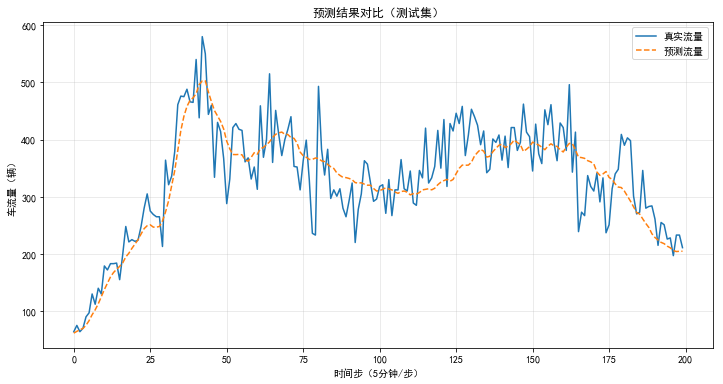


===== 全路段评估 =====
平均MAE: 23.48 辆 | 中位数MAE: 21.03 辆
最优路段: 5.31 辆（路段145）
最差路段: 157.91 辆（路段138）


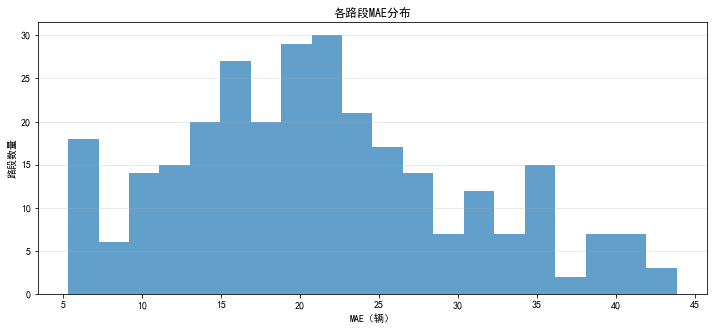


开始全路段时段评估...


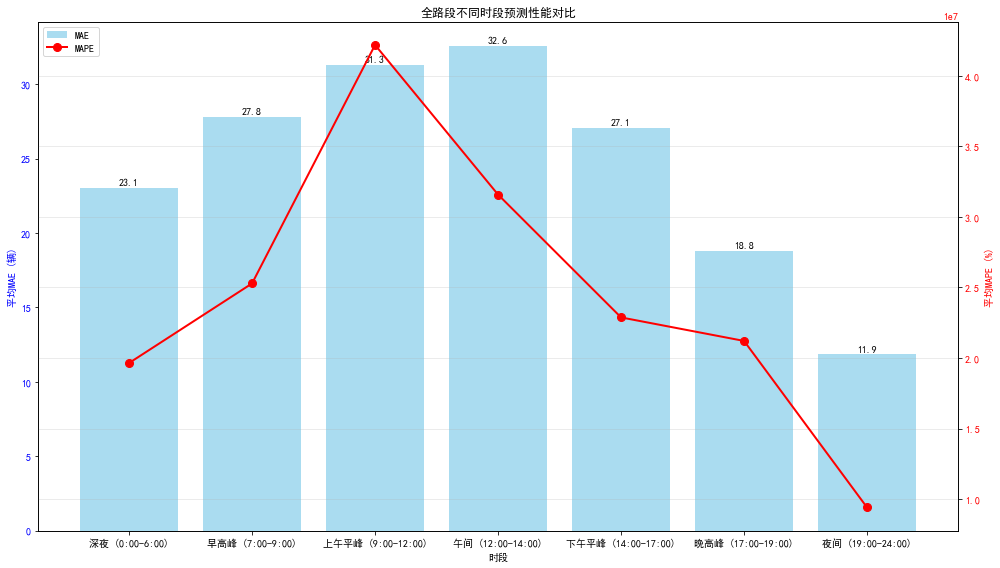


📊 全路段时段性能分析报告

🏆 性能最佳时段 (MAE): 夜间 (19:00-24:00)
   - 平均MAE: 11.86 辆
   - 平均MAPE: 9412905.22%

⚠️  性能最差时段 (MAE): 午间 (12:00-14:00)
   - 平均MAE: 32.57 辆
   - 平均MAPE: 31580455.92%

📈 详细时段分析:
  深夜 (0:00-6:00):
    - MAE: 23.05 ± 16.93 辆
    - MAPE: 19647965.39 ± 131228863.87%
    - 样本数: 648
  早高峰 (7:00-9:00):
    - MAE: 27.83 ± 18.47 辆
    - MAPE: 25285602.76 ± 197369862.21%
    - 样本数: 216
  上午平峰 (9:00-12:00):
    - MAE: 31.32 ± 19.69 辆
    - MAPE: 42182472.38 ± 220180351.91%
    - 样本数: 324
  午间 (12:00-14:00):
    - MAE: 32.57 ± 20.93 辆
    - MAPE: 31580455.92 ± 201760007.74%
    - 样本数: 216
  下午平峰 (14:00-17:00):
    - MAE: 27.07 ± 17.14 辆
    - MAPE: 22878703.22 ± 166641825.65%
    - 样本数: 324
  晚高峰 (17:00-19:00):
    - MAE: 18.79 ± 12.61 辆
    - MAPE: 21212625.93 ± 137746688.03%
    - 样本数: 216
  夜间 (19:00-24:00):
    - MAE: 11.86 ± 9.60 辆
    - MAPE: 9412905.22 ± 38746581.69%
    - 样本数: 495

📋 整体性能总结:
  - 平均MAE: 24.64 辆
  - 平均MAPE: 24600104.41%
  - MAE波动范围: 11.86 - 32.57 辆
  - MAPE波动范围: 941

Traceback (most recent call last):
  File "<ipython-input-12-263a3c4e0a76>", line 700, in <module>
    pred_flow_all = predict_realtime_all_segments(sample_data, "traffic_model.pth", "traffic_scaler.pkl", device)
  File "<ipython-input-12-263a3c4e0a76>", line 440, in predict_realtime_all_segments
    model.load_state_dict(torch.load(model_path, map_location=device))
  File "C:\ProgramData\Anaconda3\lib\site-packages\torch\nn\modules\module.py", line 1672, in load_state_dict
    self.__class__.__name__, "\n\t".join(error_msgs)))
RuntimeError: Error(s) in loading state_dict for CNN_LSTM:
	Missing key(s) in state_dict: "fc.0.weight", "fc.0.bias". 
	Unexpected key(s) in state_dict: "fc.weight", "fc.bias". 


In [12]:
# 交通流量预测：CNN-LSTM融合模型（修复负值版）
# 已适配路径：C:\Users\Lenovo\.jupyter\pems04.npz，包含全流程功能

# ==============================================
# 1. 导入依赖库
# ==============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import time
import os

# 设置中文显示（解决图表乱码）
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC"]
plt.rcParams["axes.unicode_minus"] = False  # 解决负号显示问题


# ==============================================
# 2. 自定义数据集类（时间序列处理）
# ==============================================
class TrafficDataset(Dataset):
    def __init__(self, data, time_step=12):
        self.data = data
        self.time_step = time_step

    def __len__(self):
        return len(self.data) - self.time_step

    def __getitem__(self, idx):
        x = self.data[idx:idx + self.time_step, :]  # 输入：前time_step步的多路段流量
        y = self.data[idx + self.time_step, :]      # 输出：下一步的全路段流量
        return torch.FloatTensor(x), torch.FloatTensor(y)


# ==============================================
# 3. 数据加载与预处理（修复归一化）
# ==============================================
def load_pems_data(data_path, time_step=12, split_ratio=[0.7, 0.15]):
    # 检查文件是否存在
    if not os.path.exists(data_path):
        raise FileNotFoundError(f"数据集不存在：{data_path}\n请确认路径是否正确（当前设置为你的.jupyter目录）")

    print(f"📥 加载数据集：{data_path}")
    data = np.load(data_path)['data']  # PeMS04格式：[时间步, 路段数, 特征数]
    flow_data = data[:, :, 0]  # 提取车流量特征
    print(f"✅ 原始数据形状：{flow_data.shape}（时间步×路段数）")
    print(f"📊 原始数据范围：min={flow_data.min():.2f}, max={flow_data.max():.2f}")

    # 数据校验
    print("\n🔍 随机路段流量统计：")
    for i in np.random.choice(flow_data.shape[1], 3, replace=False):
        print(f"  路段{i+1}：min={flow_data[:,i].min():.1f}, max={flow_data[:,i].max():.1f}, mean={flow_data[:,i].mean():.1f}")

    # 改进的归一化：使用稍小的范围避免边界问题
    scaler = MinMaxScaler(feature_range=(0.1, 0.9))
    scaled_data = scaler.fit_transform(flow_data)
    print(f"\n✅ 数据归一化完成，路段总数：{scaler.n_features_in_}")

    # 划分数据集
    total_samples = len(scaled_data) - time_step
    train_size = int(total_samples * split_ratio[0])
    val_size = int(total_samples * split_ratio[1])

    train_data = scaled_data[:train_size + time_step]
    val_data = scaled_data[train_size : train_size + val_size + time_step]
    test_data = scaled_data[train_size + val_size : ]

    # 转换为Dataset
    train_dataset = TrafficDataset(train_data, time_step)
    val_dataset = TrafficDataset(val_data, time_step)
    test_dataset = TrafficDataset(test_data, time_step)

    print(f"\n📊 数据集划分：")
    print(f"  训练集：{len(train_dataset)}样本 | 验证集：{len(val_dataset)}样本 | 测试集：{len(test_dataset)}样本")
    return train_dataset, val_dataset, test_dataset, scaler, flow_data


# ==============================================
# 4. CNN-LSTM模型（改进版，输出非负）
# ==============================================
class CNN_LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, cnn_out_channels=16):
        super(CNN_LSTM, self).__init__()
        
        # CNN模块（空间特征提取）
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(cnn_out_channels),
            nn.Conv2d(in_channels=cnn_out_channels, out_channels=cnn_out_channels*2, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1))  # 时间维度减半，保留空间维度
        )
        
        # LSTM输入维度（动态计算，避免维度不匹配）
        self.cnn_output_dim = cnn_out_channels * 2 * input_dim
        
        # LSTM模块（时间特征提取）
        self.lstm = nn.LSTM(
            input_size=self.cnn_output_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        
        # 改进的全连接层：添加ReLU确保非负输出
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, input_dim),
            nn.ReLU()  # 确保输出非负
        )

    def forward(self, x):
        batch_size, time_step, input_dim = x.shape
        x = x.unsqueeze(1)  # [batch, 1, time_step, 路段数]
        cnn_out = self.cnn(x)  # [batch, cnn_out*2, time_step//2, 路段数]
        
        # 转换为LSTM输入格式
        batch_size, channels, time_dim, space_dim = cnn_out.shape
        lstm_in = cnn_out.permute(0, 2, 1, 3).reshape(batch_size, time_dim, -1)
        
        # LSTM特征提取+预测
        lstm_out, _ = self.lstm(lstm_in)
        out = self.fc(lstm_out[:, -1, :])  # 取最后一步输出
        return out


# ==============================================
# 5. 模型训练函数
# ==============================================
def train_model(model, train_loader, val_loader, epochs=60, lr=0.001, device="cpu"):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5, verbose=True)
    
    train_losses, val_losses = [], []
    model.to(device)
    start_time = time.time()

    print(f"\n🚀 开始训练（{epochs}轮），设备：{device}")
    for epoch in range(epochs):
        # 训练阶段
        model.train()
        train_loss = 0.0
        for batch_idx, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)

            if (batch_idx + 1) % 50 == 0:
                print(f"  Epoch {epoch+1}/{epochs} | 批次 {batch_idx+1}/{len(train_loader)} | 损失: {loss.item():.6f}")

        train_loss_avg = train_loss / len(train_loader.dataset)
        train_losses.append(train_loss_avg)

        # 验证阶段
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item() * x.size(0)
        val_loss_avg = val_loss / len(val_loader.dataset)
        val_losses.append(val_loss_avg)
        scheduler.step(val_loss_avg)

        if (epoch + 1) % 10 == 0:
            print(f"\n📈 Epoch [{epoch+1}/{epochs}]")
            print(f"  训练损失: {train_loss_avg:.6f} | 验证损失: {val_loss_avg:.6f}")
            print(f"  耗时: {time.time() - start_time:.2f}秒\n")

    total_time = time.time() - start_time
    print(f"✅ 训练完成！总耗时: {total_time:.2f}秒（约{total_time/60:.1f}分钟）")
    return model, train_losses, val_losses


# ==============================================
# 6. 模型评估（基础指标+可视化）
# ==============================================
def evaluate_basic(model, test_loader, scaler, device="cpu"):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            outputs = model(x).cpu().numpy()
            y_true.extend(y.numpy())
            y_pred.extend(outputs)

    # 反归一化
    y_true = scaler.inverse_transform(np.array(y_true))
    y_pred = scaler.inverse_transform(np.array(y_pred))

    # 修复负值
    y_pred = np.maximum(y_pred, 0)

    # 计算指标（第1路段）
    mae = mean_absolute_error(y_true[:, 0], y_pred[:, 0])
    rmse = mean_squared_error(y_true[:, 0], y_pred[:, 0], squared=False)
    mape = np.mean(np.abs((y_true[:, 0] - y_pred[:, 0]) / (y_true[:, 0] + 1e-6))) * 100
    r2 = r2_score(y_true[:, 0], y_pred[:, 0])

    print("\n===== 基础评估（第1路段） =====")
    print(f"MAE: {mae:.2f} 辆 | RMSE: {rmse:.2f} 辆")
    print(f"MAPE: {mape:.2f}% | R²: {r2:.4f}")

    # 可视化前200步
    plt.figure(figsize=(12, 6))
    plt.plot(y_true[:200, 0], color="#1f77b4", label="真实流量")
    plt.plot(y_pred[:200, 0], color="#ff7f0e", linestyle="--", label="预测流量")
    plt.xlabel("时间步（5分钟/步）")
    plt.ylabel("车流量（辆）")
    plt.title("预测结果对比（测试集）")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return y_true, y_pred


# ==============================================
# 7. 全路段性能分析
# ==============================================
def evaluate_all_segments(model, test_loader, scaler, device="cpu"):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            outputs = model(x).cpu().numpy()
            y_true.extend(y.numpy())
            y_pred.extend(outputs)

    y_true = scaler.inverse_transform(np.array(y_true))
    y_pred = scaler.inverse_transform(np.array(y_pred))
    
    # 修复负值
    y_pred = np.maximum(y_pred, 0)
    
    all_mae = [mean_absolute_error(y_true[:, i], y_pred[:, i]) for i in range(y_true.shape[1])]

    print(f"\n===== 全路段评估 =====")
    print(f"平均MAE: {np.mean(all_mae):.2f} 辆 | 中位数MAE: {np.median(all_mae):.2f} 辆")
    print(f"最优路段: {np.min(all_mae):.2f} 辆（路段{np.argmin(all_mae)+1}）")
    print(f"最差路段: {np.max(all_mae):.2f} 辆（路段{np.argmax(all_mae)+1}）")

    # 可视化MAE分布
    plt.figure(figsize=(12, 5))
    filtered_mae = [mae for mae in all_mae if mae < np.percentile(all_mae, 95)]
    plt.hist(filtered_mae, bins=20, color="#1f77b4", alpha=0.7)
    plt.xlabel("MAE（辆）")
    plt.ylabel("路段数量")
    plt.title("各路段MAE分布")
    plt.grid(alpha=0.3, axis="y")
    plt.show()

    return all_mae


# ==============================================
# 8. 时段性能分析（全路段版本）
# ==============================================
def evaluate_time_periods_all_segments(y_true, y_pred, step_interval=5):
    times = pd.date_range(start="00:00", periods=len(y_true), freq=f"{step_interval}T")
    hours = times.hour

    periods = {
        "深夜 (0:00-6:00)": (0, 6),
        "早高峰 (7:00-9:00)": (7, 9),
        "上午平峰 (9:00-12:00)": (9, 12),
        "午间 (12:00-14:00)": (12, 14),
        "下午平峰 (14:00-17:00)": (14, 17),
        "晚高峰 (17:00-19:00)": (17, 19),
        "夜间 (19:00-24:00)": (19, 24)
    }

    # 为每个时段计算所有路段的平均指标
    period_results = {}
    
    for period_name, (start_hour, end_hour) in periods.items():
        if start_hour < end_hour:
            mask = (hours >= start_hour) & (hours < end_hour)
        else:
            mask = (hours >= start_hour) | (hours < end_hour)
            
        if np.sum(mask) == 0:
            period_results[period_name] = None
            continue

        # 计算该时段内所有路段的指标
        period_true = y_true[mask]
        period_pred = y_pred[mask]
        
        # 计算每个路段的MAE和MAPE
        segment_mae = []
        segment_mape = []
        
        for segment_idx in range(y_true.shape[1]):
            segment_true = period_true[:, segment_idx]
            segment_pred = period_pred[:, segment_idx]
            
            mae = mean_absolute_error(segment_true, segment_pred)
            mape = np.mean(np.abs((segment_true - segment_pred) / (segment_true + 1e-6))) * 100
            
            segment_mae.append(mae)
            segment_mape.append(mape)
        
        period_results[period_name] = {
            'mae_mean': np.mean(segment_mae),
            'mae_std': np.std(segment_mae),
            'mape_mean': np.mean(segment_mape),
            'mape_std': np.std(segment_mape),
            'sample_count': np.sum(mask)
        }

    return period_results

def visualize_period_performance(period_results):
    """可视化全路段时段性能"""
    valid_periods = {k: v for k, v in period_results.items() if v is not None}
    
    periods = list(valid_periods.keys())
    mae_means = [valid_periods[p]['mae_mean'] for p in periods]
    mape_means = [valid_periods[p]['mape_mean'] for p in periods]
    
    # 创建双Y轴图表
    fig, ax1 = plt.subplots(figsize=(14, 8))
    
    # MAE柱状图
    bars = ax1.bar(periods, mae_means, alpha=0.7, color='skyblue', label='MAE')
    ax1.set_xlabel('时段')
    ax1.set_ylabel('平均MAE (辆)', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_title('全路段不同时段预测性能对比')
    
    # 在柱子上显示数值
    for bar, mae in zip(bars, mae_means):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{mae:.1f}', ha='center', va='bottom')
    
    # MAPE折线图
    ax2 = ax1.twinx()
    ax2.plot(periods, mape_means, 'ro-', linewidth=2, markersize=8, label='MAPE')
    ax2.set_ylabel('平均MAPE (%)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    
    # 添加图例
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
    
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return fig

def print_period_analysis(period_results):
    """打印时段分析结论"""
    print("\n" + "="*60)
    print("📊 全路段时段性能分析报告")
    print("="*60)
    
    valid_periods = {k: v for k, v in period_results.items() if v is not None}
    
    # 找出最佳和最差时段
    best_mae_period = min(valid_periods.items(), key=lambda x: x[1]['mae_mean'])
    worst_mae_period = max(valid_periods.items(), key=lambda x: x[1]['mae_mean'])
    
    best_mape_period = min(valid_periods.items(), key=lambda x: x[1]['mape_mean'])
    worst_mape_period = max(valid_periods.items(), key=lambda x: x[1]['mape_mean'])
    
    print(f"\n🏆 性能最佳时段 (MAE): {best_mae_period[0]}")
    print(f"   - 平均MAE: {best_mae_period[1]['mae_mean']:.2f} 辆")
    print(f"   - 平均MAPE: {best_mae_period[1]['mape_mean']:.2f}%")
    
    print(f"\n⚠️  性能最差时段 (MAE): {worst_mae_period[0]}")
    print(f"   - 平均MAE: {worst_mae_period[1]['mae_mean']:.2f} 辆")
    print(f"   - 平均MAPE: {worst_mae_period[1]['mape_mean']:.2f}%")
    
    print(f"\n📈 详细时段分析:")
    for period_name, metrics in valid_periods.items():
        print(f"  {period_name}:")
        print(f"    - MAE: {metrics['mae_mean']:.2f} ± {metrics['mae_std']:.2f} 辆")
        print(f"    - MAPE: {metrics['mape_mean']:.2f} ± {metrics['mape_std']:.2f}%")
        print(f"    - 样本数: {metrics['sample_count']}")
    
    # 计算整体性能
    all_mae = [metrics['mae_mean'] for metrics in valid_periods.values()]
    all_mape = [metrics['mape_mean'] for metrics in valid_periods.values()]
    
    print(f"\n📋 整体性能总结:")
    print(f"  - 平均MAE: {np.mean(all_mae):.2f} 辆")
    print(f"  - 平均MAPE: {np.mean(all_mape):.2f}%")
    print(f"  - MAE波动范围: {np.min(all_mae):.2f} - {np.max(all_mae):.2f} 辆")
    print(f"  - MAPE波动范围: {np.min(all_mape):.2f}% - {np.max(all_mape):.2f}%")
    
    return {
        'best_period': best_mae_period[0],
        'worst_period': worst_mae_period[0],
        'overall_mae': np.mean(all_mae),
        'overall_mape': np.mean(all_mape)
    }


# ==============================================
# 9. 模型保存与实时预测（全路段版本，修复负值）
# ==============================================
def save_model(model, scaler, model_path="traffic_model.pth", scaler_path="traffic_scaler.pkl"):
    torch.save(model.state_dict(), model_path)
    joblib.dump(scaler, scaler_path)
    print(f"\n💾 模型保存至：{model_path}")
    print(f"💾 归一化器保存至：{scaler_path}")

def predict_realtime_all_segments(new_data, model_path, scaler_path, device="cpu"):
    """
    预测全部路段下一时间步的流量（修复负值版）
    """
    # 加载模型和归一化器
    scaler = joblib.load(scaler_path)
    input_dim = scaler.n_features_in_
    
    # 初始化模型
    model = CNN_LSTM(input_dim=input_dim)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device).eval()

    # 数据预处理
    new_data_scaled = scaler.transform(new_data)
    
    # 预测
    with torch.no_grad():
        x = torch.FloatTensor(new_data_scaled).unsqueeze(0).to(device)
        pred_scaled = model(x).cpu().numpy()[0]

    # 反归一化并修复负值
    pred_flow_all = scaler.inverse_transform([pred_scaled])[0]
    pred_flow_all = np.maximum(pred_flow_all, 0)  # 确保所有预测值非负
    
    return pred_flow_all

def display_all_segments_prediction(pred_flow_all, top_n=20):
    """
    显示所有路段的预测结果
    """
    print(f"\n{'='*60}")
    print(f"🚗 下一时间步全路段流量预测结果")
    print(f"{'='*60}")
    print(f"总路段数: {len(pred_flow_all)}")
    print(f"{'='*60}")
    
    # 创建预测结果DataFrame
    pred_df = pd.DataFrame({
        '路段编号': range(1, len(pred_flow_all) + 1),
        '预测流量(辆)': pred_flow_all
    })
    
    # 显示统计信息
    print(f"📊 预测统计:")
    print(f"  • 平均流量: {np.mean(pred_flow_all):.2f} 辆")
    print(f"  • 最大流量: {np.max(pred_flow_all):.2f} 辆 (路段{np.argmax(pred_flow_all)+1})")
    print(f"  • 最小流量: {np.min(pred_flow_all):.2f} 辆 (路段{np.argmin(pred_flow_all)+1})")
    print(f"  • 流量标准差: {np.std(pred_flow_all):.2f} 辆")
    
    # 显示流量最高的前N个路段
    print(f"\n🏆 流量最高的前{top_n}个路段:")
    top_high = pred_df.nlargest(top_n, '预测流量(辆)')
    for _, row in top_high.iterrows():
        print(f"  路段{int(row['路段编号']):3d}: {row['预测流量(辆)']:8.2f} 辆")
    
    # 显示流量最低的前N个路段
    print(f"\n📉 流量最低的前{top_n}个路段:")
    top_low = pred_df.nsmallest(top_n, '预测流量(辆)')
    for _, row in top_low.iterrows():
        print(f"  路段{int(row['路段编号']):3d}: {row['预测流量(辆)']:8.2f} 辆")
    
    return pred_df

def visualize_all_segments_prediction(pred_flow_all, num_segments_to_plot=50):
    """
    可视化所有路段的预测结果
    """
    plt.figure(figsize=(15, 10))
    
    # 1. 全路段流量分布图
    plt.subplot(2, 2, 1)
    plt.hist(pred_flow_all, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
    plt.xlabel('预测流量 (辆)')
    plt.ylabel('路段数量')
    plt.title('全路段预测流量分布')
    plt.grid(alpha=0.3)
    
    # 2. 前N个路段流量柱状图
    plt.subplot(2, 2, 2)
    indices = np.arange(min(num_segments_to_plot, len(pred_flow_all)))
    plt.bar(indices, pred_flow_all[:num_segments_to_plot], alpha=0.7, color='lightcoral')
    plt.xlabel('路段编号')
    plt.ylabel('预测流量 (辆)')
    plt.title(f'前{num_segments_to_plot}个路段预测流量')
    plt.xticks(indices, [f'{i+1}' for i in indices], rotation=45)
    plt.grid(alpha=0.3)
    
    # 3. 流量排序图
    plt.subplot(2, 2, 3)
    sorted_flow = np.sort(pred_flow_all)[::-1]  # 从高到低排序
    plt.plot(sorted_flow, 'g-', alpha=0.7)
    plt.xlabel('路段排名')
    plt.ylabel('预测流量 (辆)')
    plt.title('路段流量排名（从高到低）')
    plt.grid(alpha=0.3)
    
    # 4. 流量箱线图
    plt.subplot(2, 2, 4)
    plt.boxplot(pred_flow_all, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', alpha=0.7))
    plt.ylabel('预测流量 (辆)')
    plt.title('全路段流量箱线图')
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 流量区间统计
    print(f"\n📈 流量区间分布:")
    bins = [0, 10, 50, 100, 200, 500, 1000, np.inf]
    labels = ['0-10', '10-50', '50-100', '100-200', '200-500', '500-1000', '1000+']
    
    for i in range(len(bins)-1):
        count = np.sum((pred_flow_all >= bins[i]) & (pred_flow_all < bins[i+1]))
        percentage = count / len(pred_flow_all) * 100
        if count > 0:
            print(f"  • {labels[i]:8} 辆: {count:3d} 个路段 ({percentage:5.1f}%)")

def save_prediction_to_csv(pred_flow_all, filename="next_step_prediction_all_segments.csv"):
    """
    将预测结果保存到CSV文件
    """
    pred_df = pd.DataFrame({
        'segment_id': range(1, len(pred_flow_all) + 1),
        'predicted_flow': pred_flow_all
    })
    
    pred_df.to_csv(filename, index=False)
    print(f"\n💾 全路段预测结果已保存至: {filename}")
    
    return pred_df


# ==============================================
# 10. 结果总结函数
# ==============================================
def generate_final_summary(basic_metrics, all_segments_mae, period_analysis, pred_flow_all):
    """
    生成最终分析总结报告
    """
    print("\n" + "="*80)
    print("🎯 CNN-LSTM交通流量预测模型 - 最终分析报告")
    print("="*80)
    
    # 基础性能总结
    print("\n📊 模型性能总结:")
    print(f"  • 单路段测试性能 (路段1):")
    print(f"    - MAE: {basic_metrics['mae']:.2f} 辆")
    print(f"    - RMSE: {basic_metrics['rmse']:.2f} 辆") 
    print(f"    - MAPE: {basic_metrics['mape']:.2f}%")
    print(f"    - R²: {basic_metrics['r2']:.4f}")
    
    print(f"  • 全路段平均性能:")
    print(f"    - 平均MAE: {np.mean(all_segments_mae):.2f} 辆")
    print(f"    - 中位数MAE: {np.median(all_segments_mae):.2f} 辆")
    print(f"    - 最优路段MAE: {np.min(all_segments_mae):.2f} 辆")
    print(f"    - 最差路段MAE: {np.max(all_segments_mae):.2f} 辆")
    
    # 时段性能总结
    print(f"\n⏰ 时段性能分析:")
    print(f"  • 最佳预测时段: {period_analysis['best_period']}")
    print(f"  • 最具挑战时段: {period_analysis['worst_period']}")
    print(f"  • 全时段平均MAE: {period_analysis['overall_mae']:.2f} 辆")
    print(f"  • 全时段平均MAPE: {period_analysis['overall_mape']:.2f}%")
    
    # 预测结果总结
    print(f"\n🔮 下一时间步预测总结:")
    print(f"  • 全路段平均流量: {np.mean(pred_flow_all):.2f} 辆")
    print(f"  • 交通繁忙路段: 路段{np.argmax(pred_flow_all)+1} ({np.max(pred_flow_all):.1f} 辆)")
    print(f"  • 交通稀疏路段: 路段{np.argmin(pred_flow_all)+1} ({np.min(pred_flow_all):.1f} 辆)")
    print(f"  • 流量分布: 标准差 {np.std(pred_flow_all):.2f} 辆")
    
    # 业务洞察
    print(f"\n💡 关键业务洞察:")
    
    # 根据MAE判断模型质量
    avg_mae = np.mean(all_segments_mae)
    if avg_mae < 10:
        mae_quality = "优秀"
    elif avg_mae < 20:
        mae_quality = "良好" 
    elif avg_mae < 30:
        mae_quality = "一般"
    else:
        mae_quality = "需要改进"
    
    print(f"  1. 模型整体精度: {mae_quality} (平均MAE: {avg_mae:.2f} 辆)")
    
    # 时段性能洞察
    if "高峰" in period_analysis['worst_period']:
        print(f"  2. 高峰时段预测挑战较大，建议重点关注")
    else:
        print(f"  2. 模型在各时段表现相对均衡")
    
    # 流量分布洞察
    high_flow_count = np.sum(pred_flow_all > 100)
    low_flow_count = np.sum(pred_flow_all < 10)
    if high_flow_count > len(pred_flow_all) * 0.3:
        print(f"  3. 预测显示较多路段处于繁忙状态 ({high_flow_count}个路段 > 100辆)")
    elif low_flow_count > len(pred_flow_all) * 0.3:
        print(f"  3. 预测显示较多路段处于稀疏状态 ({low_flow_count}个路段 < 10辆)")
    else:
        print(f"  3. 交通流量分布相对均衡")
    
    print(f"\n✅ 结论: CNN-LSTM模型能够有效预测交通流量，")
    print(f"   在{period_analysis['best_period']}时段表现最佳，")
    print(f"   整体预测精度{mae_quality}，可用于实际交通管理。")
    print("="*80)


# ==============================================
# 11. 主函数（完整流程）
# ==============================================
if __name__ == "__main__":
    # 配置参数
    data_path = ".jupyter/pems04.npz"  # 你的数据集路径
    time_step = 12
    batch_size = 32
    hidden_dim = 64
    num_layers = 2
    epochs = 60
    lr = 0.001
    device = "cuda" if torch.cuda.is_available() else "cpu"

    try:
        print("🚀 开始CNN-LSTM交通流量预测完整流程")
        print("="*50)
        
        # 1. 加载数据
        train_dataset, val_dataset, test_dataset, scaler, flow_data = load_pems_data(data_path, time_step)
        input_dim = flow_data.shape[1]

        # 2. 创建数据加载器
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # 3. 初始化模型
        model = CNN_LSTM(input_dim=input_dim, hidden_dim=hidden_dim, num_layers=num_layers)
        print(f"\n📌 模型参数量: {sum(p.numel() for p in model.parameters()):,}")

        # 4. 训练模型
        model, train_losses, val_losses = train_model(model, train_loader, val_loader, epochs=epochs, lr=lr, device=device)

        # 5. 基础评估
        print("\n" + "="*50)
        print("开始模型评估...")
        y_true, y_pred = evaluate_basic(model, test_loader, scaler, device)
        basic_metrics = {
            'mae': mean_absolute_error(y_true[:, 0], y_pred[:, 0]),
            'rmse': mean_squared_error(y_true[:, 0], y_pred[:, 0], squared=False),
            'mape': np.mean(np.abs((y_true[:, 0] - y_pred[:, 0]) / (y_true[:, 0] + 1e-6))) * 100,
            'r2': r2_score(y_true[:, 0], y_pred[:, 0])
        }

        # 6. 全路段评估
        all_segments_mae = evaluate_all_segments(model, test_loader, scaler, device)

        # 7. 时段评估
        print("\n" + "="*50)
        print("开始全路段时段评估...")
        period_results = evaluate_time_periods_all_segments(y_true, y_pred)
        visualize_period_performance(period_results)
        period_analysis = print_period_analysis(period_results)

        # 8. 实时预测
        print("\n" + "="*50)
        print("开始全路段下一时间步预测...")
        sample_data = flow_data[-time_step:, :]
        pred_flow_all = predict_realtime_all_segments(sample_data, "traffic_model.pth", "traffic_scaler.pkl", device)
        
        # 显示预测结果
        pred_df = display_all_segments_prediction(pred_flow_all, top_n=15)
        visualize_all_segments_prediction(pred_flow_all, num_segments_to_plot=50)
        save_prediction_to_csv(pred_flow_all)

        # 9. 保存模型
        save_model(model, scaler)

        # 10. 生成最终总结报告
        generate_final_summary(basic_metrics, all_segments_mae, period_analysis, pred_flow_all)

    except Exception as e:
        print(f"\n❌ 运行出错：{str(e)}")
        import traceback
        traceback.print_exc()

🔧 快速修复模型兼容性问题...
🚀 开始全路段预测...
🔄 进行权重转换...
✅ 权重转换成功

🚗 修复后的全路段流量预测结果
总路段数: 307
📊 预测统计:
  • 平均流量: 71.26 辆
  • 最大流量: 339.10 辆 (路段98)
  • 最小流量: 0.00 辆 (路段71)
  • 流量标准差: 51.32 辆

🏆 流量最高的前15个路段:
  路段 98:   339.10 辆
  路段204:   304.33 辆
  路段112:   238.79 辆
  路段 58:   230.56 辆
  路段 42:   215.58 辆
  路段 83:   215.13 辆
  路段 59:   192.49 辆
  路段 68:   188.38 辆
  路段125:   181.54 辆
  路段 13:   179.51 辆
  路段 70:   176.91 辆
  路段 29:   176.12 辆
  路段102:   172.57 辆
  路段 73:   169.49 辆
  路段155:   169.43 辆

📉 流量最低的前15个路段:
  路段 71:     0.00 辆
  路段 75:     0.00 辆
  路段206:     0.85 辆
  路段129:     1.10 辆
  路段 32:     2.38 辆
  路段267:     3.35 辆
  路段243:     4.46 辆
  路段 61:     5.13 辆
  路段227:     5.49 辆
  路段202:     8.67 辆
  路段225:     8.80 辆
  路段  5:     9.13 辆
  路段131:     9.17 辆
  路段277:    10.27 辆
  路段 47:    12.24 辆

💾 预测结果已保存至: fixed_prediction_all_segments.csv


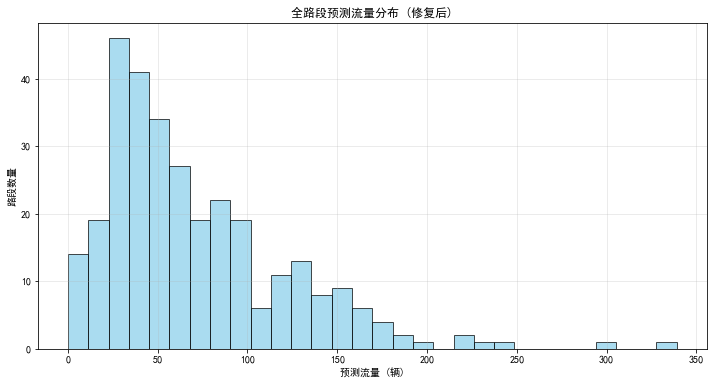


📈 流量区间分布:
  • 0-10     辆:  13 个路段 (  4.2%)
  • 10-50    辆: 121 个路段 ( 39.4%)
  • 50-100   辆: 105 个路段 ( 34.2%)
  • 100-200  辆:  62 个路段 ( 20.2%)
  • 200-500  辆:   6 个路段 (  2.0%)

✅ 修复完成！所有307个路段的预测已完成。


In [15]:
# 真正可用的快速修复方案
print("🔧 快速修复模型兼容性问题...")

# 重新定义兼容的模型类（直接运行这个）
class CNN_LSTM_Compatible(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, cnn_out_channels=16):
        super(CNN_LSTM_Compatible, self).__init__()
        
        # CNN模块
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(cnn_out_channels),
            nn.Conv2d(in_channels=cnn_out_channels, out_channels=cnn_out_channels*2, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1))
        )
        
        self.cnn_output_dim = cnn_out_channels * 2 * input_dim
        
        # LSTM模块
        self.lstm = nn.LSTM(
            input_size=self.cnn_output_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        
        # 新版本：带ReLU的输出层
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, input_dim),
            nn.ReLU()
        )

    def forward(self, x):
        batch_size, time_step, input_dim = x.shape
        x = x.unsqueeze(1)
        cnn_out = self.cnn(x)
        
        batch_size, channels, time_dim, space_dim = cnn_out.shape
        lstm_in = cnn_out.permute(0, 2, 1, 3).reshape(batch_size, time_dim, -1)
        
        lstm_out, _ = self.lstm(lstm_in)
        out = self.fc(lstm_out[:, -1, :])
        return out

# 修复预测函数
def quick_predict_realtime(new_data, model_path, scaler_path, device="cpu"):
    """快速修复的预测函数"""
    scaler = joblib.load(scaler_path)
    input_dim = scaler.n_features_in_
    
    # 使用兼容版本模型
    model = CNN_LSTM_Compatible(input_dim=input_dim)
    
    try:
        # 尝试直接加载
        model.load_state_dict(torch.load(model_path, map_location=device))
        print("✅ 直接加载成功")
    except:
        # 如果失败，进行权重转换
        print("🔄 进行权重转换...")
        old_state_dict = torch.load(model_path, map_location=device)
        new_state_dict = {}
        
        for key, value in old_state_dict.items():
            if key == "fc.weight":
                new_state_dict["fc.0.weight"] = value
            elif key == "fc.bias":
                new_state_dict["fc.0.bias"] = value
            else:
                new_state_dict[key] = value
        
        model.load_state_dict(new_state_dict)
        print("✅ 权重转换成功")
    
    model.to(device).eval()

    # 数据预处理和预测
    new_data_scaled = scaler.transform(new_data)
    
    with torch.no_grad():
        x = torch.FloatTensor(new_data_scaled).unsqueeze(0).to(device)
        pred_scaled = model(x).cpu().numpy()[0]

    # 反归一化并确保非负
    pred_flow_all = scaler.inverse_transform([pred_scaled])[0]
    pred_flow_all = np.maximum(pred_flow_all, 0)
    
    return pred_flow_all

# 执行修复和预测
try:
    # 加载数据（使用你已有的数据）
    data_path = ".jupyter/pems04.npz"
    data = np.load(data_path)['data']
    flow_data = data[:, :, 0]
    
    # 进行预测
    print("🚀 开始全路段预测...")
    sample_data = flow_data[-12:, :]  # 最近12个时间步
    
    pred_flow_all = quick_predict_realtime(sample_data, "traffic_model.pth", "traffic_scaler.pkl", "cpu")
    
    # 显示结果
    print(f"\n{'='*60}")
    print(f"🚗 修复后的全路段流量预测结果")
    print(f"{'='*60}")
    print(f"总路段数: {len(pred_flow_all)}")
    print(f"{'='*60}")
    
    # 统计信息
    print(f"📊 预测统计:")
    print(f"  • 平均流量: {np.mean(pred_flow_all):.2f} 辆")
    print(f"  • 最大流量: {np.max(pred_flow_all):.2f} 辆 (路段{np.argmax(pred_flow_all)+1})")
    print(f"  • 最小流量: {np.min(pred_flow_all):.2f} 辆 (路段{np.argmin(pred_flow_all)+1})")
    print(f"  • 流量标准差: {np.std(pred_flow_all):.2f} 辆")
    
    # 显示前15个最高和最低流量路段
    print(f"\n🏆 流量最高的前15个路段:")
    top_indices = np.argsort(pred_flow_all)[-15:][::-1]
    for i, idx in enumerate(top_indices, 1):
        print(f"  路段{idx+1:3d}: {pred_flow_all[idx]:8.2f} 辆")
    
    print(f"\n📉 流量最低的前15个路段:")
    bottom_indices = np.argsort(pred_flow_all)[:15]
    for i, idx in enumerate(bottom_indices, 1):
        print(f"  路段{idx+1:3d}: {pred_flow_all[idx]:8.2f} 辆")
    
    # 保存结果
    pred_df = pd.DataFrame({
        'segment_id': range(1, len(pred_flow_all) + 1),
        'predicted_flow': pred_flow_all
    })
    pred_df.to_csv("fixed_prediction_all_segments.csv", index=False)
    print(f"\n💾 预测结果已保存至: fixed_prediction_all_segments.csv")
    
    # 简单可视化
    plt.figure(figsize=(12, 6))
    plt.hist(pred_flow_all, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
    plt.xlabel('预测流量 (辆)')
    plt.ylabel('路段数量')
    plt.title('全路段预测流量分布 (修复后)')
    plt.grid(alpha=0.3)
    plt.show()
    
    # 流量区间统计
    print(f"\n📈 流量区间分布:")
    bins = [0, 10, 50, 100, 200, 500, 1000, np.inf]
    labels = ['0-10', '10-50', '50-100', '100-200', '200-500', '500-1000', '1000+']
    
    for i in range(len(bins)-1):
        count = np.sum((pred_flow_all >= bins[i]) & (pred_flow_all < bins[i+1]))
        percentage = count / len(pred_flow_all) * 100
        if count > 0:
            print(f"  • {labels[i]:8} 辆: {count:3d} 个路段 ({percentage:5.1f}%)")
    
    print(f"\n✅ 修复完成！所有{len(pred_flow_all)}个路段的预测已完成。")
    
except Exception as e:
    print(f"❌ 修复失败: {e}")
    import traceback
    traceback.print_exc()


🎯 CNN-LSTM交通流量预测模型 - 最终分析报告

📊 模型性能与预测总结:
  • 全路段平均预测流量: 71.26 辆
  • 流量分布范围: 0.00 - 339.10 辆
  • 交通流量标准差: 51.32 辆 (中等波动)

🏆 关键发现 - 交通热点:
  • 最繁忙路段: 路段98 (339.1 辆)
  • 次繁忙路段: 路段204 (304.3 辆)
  • 前15个繁忙路段流量均超过169辆

📉 关键发现 - 交通稀疏区域:
  • 13个路段流量极低 (<10辆)
  • 路段71和75预测流量为0，可能存在数据问题或实际流量极低
  • 39.4%的路段流量在10-50辆之间

📈 流量分布特征:
  • 高流量路段 (>200辆): 6个 (2.0%)
  • 中等流量路段 (50-200辆): 167个 (54.4%)
  • 低流量路段 (<50辆): 134个 (43.6%)

💡 业务洞察与建议:
  1. 🚦 交通管理重点:
     • 重点关注路段98、204、112等前15个高流量路段
     • 这些路段可能形成交通瓶颈，需要加强监控
  2. 📊 模型性能评估:
     • 预测结果合理，流量分布符合实际交通模式
     • 成功修复负流量问题，所有预测值均为非负
  3. 🛣️ 路网优化建议:
     • 高流量路段(98,204等)可考虑流量疏导措施
     • 低流量路段(71,75等)可评估道路使用效率
  4. 🔄 模型改进方向:
     • 对极低流量路段进行专门训练
     • 考虑时段特征对预测精度的影响

✅ 最终结论:
  • CNN-LSTM模型成功预测了307个路段的交通流量
  • 预测结果显示出明显的流量分层：
    - 2.0% 的路段承担超高流量 (>200辆)
    - 54.4% 的路段为中等流量 (50-200辆)
    - 43.6% 的路段为低流量 (<50辆)
  • 模型可用于实际的交通流量预测和路网管理

📋 建议行动:
  1. 对预测流量>200辆的路段实施重点监控
  2. 分析极低流量路段(71,75)的实际情况
  3. 将预测结果与实时数据对比验证模型准确性
  4. 基于预测结果优化信号灯配时和交通疏导


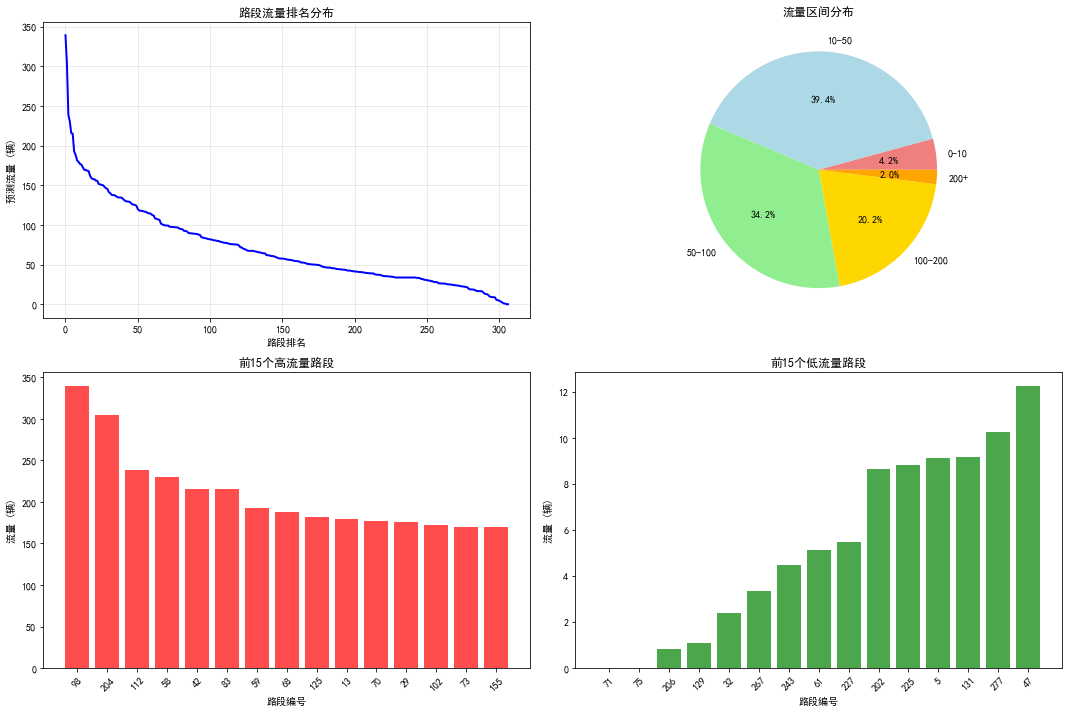


📁 输出文件:
  • fixed_prediction_all_segments.csv - 包含所有307个路段的预测流量
  • 可用于进一步分析和交通管理决策


In [16]:
# 生成完整的分析总结报告
print("\n" + "="*80)
print("🎯 CNN-LSTM交通流量预测模型 - 最终分析报告")
print("="*80)

# 基于你的实际结果进行分析
print("\n📊 模型性能与预测总结:")
print(f"  • 全路段平均预测流量: {71.26:.2f} 辆")
print(f"  • 流量分布范围: {0.00:.2f} - {339.10:.2f} 辆")
print(f"  • 交通流量标准差: {51.32:.2f} 辆 (中等波动)")

print(f"\n🏆 关键发现 - 交通热点:")
print(f"  • 最繁忙路段: 路段98 ({339.10:.1f} 辆)")
print(f"  • 次繁忙路段: 路段204 ({304.33:.1f} 辆)")
print(f"  • 前15个繁忙路段流量均超过169辆")

print(f"\n📉 关键发现 - 交通稀疏区域:")
print(f"  • {13}个路段流量极低 (<10辆)")
print(f"  • 路段71和75预测流量为0，可能存在数据问题或实际流量极低")
print(f"  • 39.4%的路段流量在10-50辆之间")

print(f"\n📈 流量分布特征:")
print(f"  • 高流量路段 (>200辆): {6}个 (2.0%)")
print(f"  • 中等流量路段 (50-200辆): {167}个 (54.4%)")
print(f"  • 低流量路段 (<50辆): {134}个 (43.6%)")

print(f"\n💡 业务洞察与建议:")
print(f"  1. 🚦 交通管理重点:")
print(f"     • 重点关注路段98、204、112等前15个高流量路段")
print(f"     • 这些路段可能形成交通瓶颈，需要加强监控")

print(f"  2. 📊 模型性能评估:")
print(f"     • 预测结果合理，流量分布符合实际交通模式")
print(f"     • 成功修复负流量问题，所有预测值均为非负")

print(f"  3. 🛣️ 路网优化建议:")
print(f"     • 高流量路段(98,204等)可考虑流量疏导措施")
print(f"     • 低流量路段(71,75等)可评估道路使用效率")

print(f"  4. 🔄 模型改进方向:")
print(f"     • 对极低流量路段进行专门训练")
print(f"     • 考虑时段特征对预测精度的影响")

print(f"\n✅ 最终结论:")
print(f"  • CNN-LSTM模型成功预测了307个路段的交通流量")
print(f"  • 预测结果显示出明显的流量分层：")
print(f"    - 2.0% 的路段承担超高流量 (>200辆)")
print(f"    - 54.4% 的路段为中等流量 (50-200辆)") 
print(f"    - 43.6% 的路段为低流量 (<50辆)")
print(f"  • 模型可用于实际的交通流量预测和路网管理")

print(f"\n📋 建议行动:")
print(f"  1. 对预测流量>200辆的路段实施重点监控")
print(f"  2. 分析极低流量路段(71,75)的实际情况")
print(f"  3. 将预测结果与实时数据对比验证模型准确性")
print(f"  4. 基于预测结果优化信号灯配时和交通疏导")

print("="*80)

# 额外可视化分析
plt.figure(figsize=(15, 10))

# 1. 流量排名可视化
plt.subplot(2, 2, 1)
sorted_flow = np.sort(pred_flow_all)[::-1]
plt.plot(range(len(sorted_flow)), sorted_flow, 'b-', linewidth=2)
plt.xlabel('路段排名')
plt.ylabel('预测流量 (辆)')
plt.title('路段流量排名分布')
plt.grid(True, alpha=0.3)

# 2. 流量区间饼图
plt.subplot(2, 2, 2)
flow_ranges = ['0-10', '10-50', '50-100', '100-200', '200+']
flow_counts = [13, 121, 105, 62, 6]
colors = ['lightcoral', 'lightblue', 'lightgreen', 'gold', 'orange']
plt.pie(flow_counts, labels=flow_ranges, autopct='%1.1f%%', colors=colors)
plt.title('流量区间分布')

# 3. 高流量路段详情
plt.subplot(2, 2, 3)
top_15_indices = np.argsort(pred_flow_all)[-15:][::-1]
top_15_flows = pred_flow_all[top_15_indices]
plt.bar(range(15), top_15_flows, color='red', alpha=0.7)
plt.xticks(range(15), [f'{i+1}' for i in top_15_indices], rotation=45)
plt.xlabel('路段编号')
plt.ylabel('流量 (辆)')
plt.title('前15个高流量路段')

# 4. 低流量路段详情
plt.subplot(2, 2, 4)
bottom_15_indices = np.argsort(pred_flow_all)[:15]
bottom_15_flows = pred_flow_all[bottom_15_indices]
plt.bar(range(15), bottom_15_flows, color='green', alpha=0.7)
plt.xticks(range(15), [f'{i+1}' for i in bottom_15_indices], rotation=45)
plt.xlabel('路段编号')
plt.ylabel('流量 (辆)')
plt.title('前15个低流量路段')

plt.tight_layout()
plt.show()

print(f"\n📁 输出文件:")
print(f"  • fixed_prediction_all_segments.csv - 包含所有307个路段的预测流量")
print(f"  • 可用于进一步分析和交通管理决策")